# Where may I fly: UAS geographical zones from ANS CR data

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/eu_rules_brno_en.ipynb)

**OpenSkyLab · notebook for the visual** [Where and how may I fly](https://openskylab.space/edu_viz_eu_rules.html) · [česká verze](eu_rules_brno_cs.ipynb)

The visual walks through the decision tree of the European drone rules. Here you go through one of its branches, UAS geographical zones, on real data: you download the current zones published by Air Navigation Services of the Czech Republic (ŘLP), find out which zones the planned flight sites fall into, how high you may fly near airports and how zones change over time. This is a teaching aid, not legal advice: before a flight always check the zones in the DroneMap app and the conditions in the CAA measures of general nature (OOP).

**Goal:** load the list of geographical zones and their GeoJSON files, determine the zones for given sites and for a whole mapping flight area, convert the vertical limits of zones (AGL, AMSL, FL) to metres above ground, read height restrictions from the grid around airports, and compare the current and the next release of the zones.

**Data:** UAS geographical zones as GeoJSON (reference boundaries) from the ŘLP page https://aim.rlp.cz/?lang=cz&p=uas-gz, downloaded at run time; terrain elevation from the Digital terrain model of the Czech Republic, 5th generation (DMR 5G, ČÚZK).

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and the list of zones

In [1]:
%pip install -q shapely pyproj rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, html, json, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point, box
import shapely
from pyproj import Transformer
import rasterio

AIM = "https://aim.rlp.cz"
def get(url, tries=4, **kw):
    for i in range(tries):
        try:
            r = requests.get(url, timeout=180, **kw); r.raise_for_status(); return r
        except requests.RequestException as e:
            print(url.split("/")[-1], type(e).__name__, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError(f"Could not download {url}")

page = get(f"{AIM}/?lang=en&p=uas-gz").content.decode("utf-8")
rows = []
for tr in re.findall(r"<tr.*?</tr>", page, re.S):
    href = re.search(r'href="(/data/uas/[^"]+\.json)"', tr)
    cols = [re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", c))).strip() for c in re.findall(r"<td[^>]*>(.*?)</td>", tr, re.S)]
    if href and len(cols) >= 4:
        url = AIM + href.group(1)
        rows.append({"zone": cols[0], "description": cols[1], "file": cols[2], "size": cols[3],
                     "release": "current" if "/actual/" in url else url.split("/")[-2], "url": url})
zones = pd.DataFrame(rows)
mb = zones["size"].str.replace(",", ".").str.extract(r"([\d.]+)\s*(kB|MB)")
zones["MB"] = mb[0].astype(float) * np.where(mb[1] == "kB", 1e-3, 1)
pd.set_option("display.max_colwidth", 70)
zones[zones.release == "current"][["zone", "description", "MB"]]

,zone,description,MB
0,LKR311A - Railway Inner Zone – Railway Administration,Area less than 5 m from the centre line of the outer track,87.98000
1,LKR311B - Railway Outer Zone – Railway Administration,Area from 5 m to 60 m from the centre line of the outer track,171.67000
2,LKR311C - Railway Inner Zone – Other Operators,Area less than 5 m from the centre line of the outer track,1.54000
3,LKR311D - Railway Outer Zone – Other Operators,Area from 5 m to 60 m from the centre line of the outer track,2.99000
4,LKR312A - Protective zone of electrical substations 110kV+,Protection Zone of Electrical Substations above 110 kV+,1.11000
5,LKR312B - VHV lines protection zone 220kV+,Protection Area of High-Voltage Power Lines (HV),1.53000
6,LKR313 - Potable Water Reservoirs,Area of Water Surface at Maximum Backwater Level (Protection Zone I),0.77510
7,LKR314A - CTR and ATZ IFR Outer Zone,Restricted Area from CTR/ATZ IFR Boundary up to Inner Zone Boundary,0.01268
8,LKR314B - CTR and ATZ IFR Inner Zone,Restricted Area <1 km from Airport Perimeter and <1 km from RWY CT...,0.05816
9,LKR314C - CTR LKPR Outer Zone,Restricted Area from CTR LKPR Boundary up to Inner Zone Boundary.,0.00245


## 2. Which zones do the flight sites fall into?

We download zones up to a chosen file size (the largest layers, e.g. densely populated areas or class III roads, have hundreds of MB and would take long to download in Colab). For each site we find out which zones it lies in and what the vertical limit of the zone is.

In [3]:
MAX_MB = 20                   # ◀ parameter: largest file to download (MB)
SITES = {                     # ◀ parameter: flight sites (latitude, longitude)
    "Bystrc, Kozí horka":                (49.2467, 16.4798),
    "Kraví hora, observatory":           (49.2040, 16.5840),
    "Mendel University, Černá Pole":     (49.2105, 16.6150),
    "Chrlice by Tuřany airport":         (49.1300, 16.6550),
    "Křtiny":                            (49.2970, 16.7440),
    "Pálava, Děvín":                     (48.8700, 16.6450),
}
current = zones[(zones.release == "current") & (zones.MB <= MAX_MB) & ~zones.file.str.startswith("GRID")]
layers = {}
for _, z in current.iterrows():
    gj = get(z.url).json()
    layers[z.file.replace(".json", "")] = [(shape(f["geometry"]), f.get("properties") or {}) for f in gj["features"] if f.get("geometry")]
print(f"downloaded {len(layers)} layers, {sum(len(v) for v in layers.values())} polygons; not downloaded (large): {', '.join(zones[(zones.release == 'current') & (zones.MB > MAX_MB)].file)}")
hits = []
for site, (lat, lon) in SITES.items():
    pt = Point(lon, lat)
    for code, feats in layers.items():
        for geom, prop in feats:
            if geom.contains(pt):
                hits.append({"site": site, "layer": code, "zone": prop.get("ident"), "vertical limits": prop.get("vertical_limit"),
                             "description": current.set_index(current.file.str.replace(".json", "")).loc[code, "description"]})
hits = pd.DataFrame(hits)
hits if len(hits) else print("no site lies in a downloaded zone")

downloaded 22 layers, 6904 polygons; not downloaded (large): LKR311A.json, LKR311B.json, LKR316.json, LKR317C.json, LKR317D.json, LKR318C.json, GRID_ATZ.json, ed_318_a1_a2_all.json


,site,layer,zone,vertical limits,description
0,"Bystrc, Kozí horka",LKR320A,LKTB1,2500 ft AMSL - FL95,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
1,"Kraví hora, observatory",LKR314A,9LKR314A,GND - 2500 ft AMSL,Restricted Area from CTR/ATZ IFR Boundary up to Inner Zone Boundary
2,"Kraví hora, observatory",LKR315C,HELLKBVIII,GND - 4000 ft AMSL,"Area around Heliports within 3000–1000 m, 1000–200 m, and <200 m f..."
3,"Kraví hora, observatory",LKR315D,PISLK004III,GND - 4000 ft AMSL,Area around Public Interest Sites (Backup Heliports) within 3000–1...
4,"Kraví hora, observatory",LKR320A,LKTB1,2500 ft AMSL - FL95,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
5,"Mendel University, Černá Pole",LKR314A,9LKR314A,GND - 2500 ft AMSL,Restricted Area from CTR/ATZ IFR Boundary up to Inner Zone Boundary
6,"Mendel University, Černá Pole",LKR315C,HELLKBPIII,GND - 4000 ft AMSL,"Area around Heliports within 3000–1000 m, 1000–200 m, and <200 m f..."
7,"Mendel University, Černá Pole",LKR315D,PISLK003III,GND - 4000 ft AMSL,Area around Public Interest Sites (Backup Heliports) within 3000–1...
8,"Mendel University, Černá Pole",LKR320A,LKTB1,2500 ft AMSL - FL95,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
9,Chrlice by Tuřany airport,LKR314A,9LKR314A,GND - 2500 ft AMSL,Restricted Area from CTR/ATZ IFR Boundary up to Inner Zone Boundary


> **✏️ Task 1.** Which zones do the individual sites lie in? Which site is free of restrictions from the downloaded layers, and why does that still not mean you may fly there (which large layers did you not download, and what could they change)? Add a site where you want to fly yourself to SITES and compare the result with the DroneMap map.

*Your answer:* 

## 3. Vertical limits of zones

A zone applies only between its lower and upper limit. Limits are given above ground (AGL), above mean sea level (AMSL) or as a flight level (FL, hundreds of feet at the standard pressure of 1013.25 hPa; here we treat it as an AMSL height for simplicity). 1 ft = 0.3048 m. Terrain elevation comes from the DMR 5G digital terrain model (ČÚZK).

In [4]:
def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

FLIGHT_AGL = 120              # ◀ parameter: planned flight height above ground (m)
def level(txt, ground):
    """Convert one limit (e.g. 'GND', '3500 ft AMSL', '120 m AGL', 'FL95') to metres above ground."""
    s = txt.strip().upper().replace(" ", "")
    if s in ("GND", "SFC"): return 0.0
    if s.startswith("FL"): return float(s[2:]) * 100 * 0.3048 - ground
    m = re.match(r"([\d.]+)(FT|M)(AGL|AMSL|MSL)", s)
    v = float(m.group(1)) * (0.3048 if m.group(2) == "FT" else 1)
    return v if m.group(3) == "AGL" else v - ground

T_JTSK = Transformer.from_crs(4326, 5514, always_xy=True)
def terrain(lat, lon):
    """Terrain elevation (m a.s.l.) from DMR 5G at a point: the centre of a small 20 × 20 m window."""
    x, y = T_JTSK.transform(lon, lat)
    z, _ = cuzk_raster("dmr5g", x - 10, y - 10, x + 10, y + 10, res=2.0)
    return float(z[z.shape[0] // 2, z.shape[1] // 2])
ground = {site: terrain(lat, lon) for site, (lat, lon) in SITES.items()}
if len(hits):
    lim = hits["vertical limits"].str.split("-", n=1, expand=True)
    hits["terrain (m AMSL)"] = hits["site"].map(ground)
    hits["lower (m AGL)"] = [level(a, g) for a, g in zip(lim[0], hits["terrain (m AMSL)"])]
    hits["upper (m AGL)"] = [level(b, g) for b, g in zip(lim[1], hits["terrain (m AMSL)"])]
    hits[f"flight at {FLIGHT_AGL} m is in the zone"] = (hits["lower (m AGL)"] <= FLIGHT_AGL) & (FLIGHT_AGL <= hits["upper (m AGL)"])
    print(hits[["site", "zone", "vertical limits", "terrain (m AMSL)", "lower (m AGL)", "upper (m AGL)", f"flight at {FLIGHT_AGL} m is in the zone"]].round(0).to_string())
airspace = pd.DataFrame([{"area": p.get("ident"), "vertical limits": p.get("vertical_limit")} for _, p in layers.get("LKR320A", [])])
print("\nAirspace areas LKR320A by vertical limits:"); print(airspace["vertical limits"].value_counts().head(10).to_string())

                             site         zone      vertical limits  terrain (m AMSL)  lower (m AGL)  upper (m AGL)  flight at 120 m is in the zone
0              Bystrc, Kozí horka        LKTB1  2500 ft AMSL - FL95             332.0          430.0         2564.0                           False
1         Kraví hora, observatory     9LKR314A   GND - 2500 ft AMSL             303.0            0.0          459.0                            True
2         Kraví hora, observatory   HELLKBVIII   GND - 4000 ft AMSL             303.0            0.0          916.0                            True
3         Kraví hora, observatory  PISLK004III   GND - 4000 ft AMSL             303.0            0.0          916.0                            True
4         Kraví hora, observatory        LKTB1  2500 ft AMSL - FL95             303.0          459.0         2593.0                           False
5   Mendel University, Černá Pole     9LKR314A   GND - 2500 ft AMSL             239.0            0.0          52

> **✏️ Task 2.** The restricted area around Brno-Tuřany airport (zone 9LKR314A) has an upper limit of 2500 ft AMSL: how many metres above ground is that on Kraví hora and in Chrlice? Why do some LKR320A airspace areas not concern a drone at 120 m at all? Why does terrain elevation matter for limits in AMSL or FL, and what does that mean on Děvín, where the LKTB4 area starts at FL65?

*Your answer:* 

## 4. The grid around controlled airports

Around controlled airports (CTR) ŘLP publishes a grid of 30″ × 30″ cells (about 600 × 900 m) where each cell states up to what height above ground flight is allowed without further approval. The conditions of using the grid are in the relevant OOP.

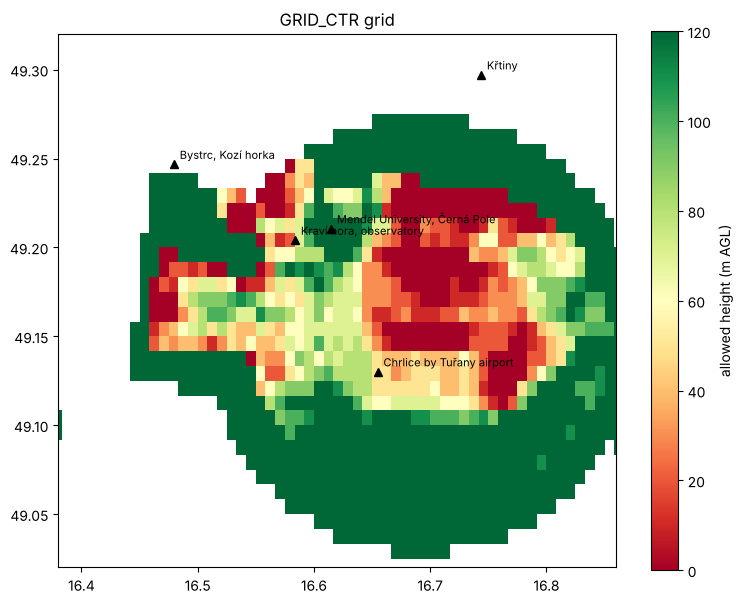

Bystrc, Kozí horka: outside the grid
Kraví hora, observatory: up to 70 m above ground
Mendel University, Černá Pole: up to 120 m above ground
Chrlice by Tuřany airport: up to 50 m above ground
Křtiny: outside the grid


Pálava, Děvín: outside the grid


In [5]:
CENTER = (49.17, 16.62)       # ◀ parameter: centre of the map (latitude, longitude)
SPAN = 0.15                   # ◀ parameter: half the extent of the map (°)
grid_url = zones[(zones.release == "current") & (zones.file == "GRID_CTR.json")].url.iloc[0]
grid = [(shape(f["geometry"]), f["properties"]["vertical_limit"]) for f in get(grid_url).json()["features"]]
hmax = lambda txt: float(re.search(r"-\s*([\d.]+)\s*m\s*AGL", txt).group(1))
fig, ax = plt.subplots(figsize=(9, 7))
view = box(CENTER[1] - SPAN * 1.6, CENTER[0] - SPAN, CENTER[1] + SPAN * 1.6, CENTER[0] + SPAN)
cmap = plt.get_cmap("RdYlGn")
for g, v in grid:
    if g.intersects(view):
        x, y = g.exterior.xy; ax.fill(x, y, color=cmap(hmax(v) / 120), lw=0)
for site, (lat, lon) in SITES.items():
    ax.plot(lon, lat, "k^"); ax.annotate(site, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(view.bounds[0], view.bounds[2]); ax.set_ylim(view.bounds[1], view.bounds[3]); ax.set_aspect(1 / np.cos(np.radians(CENTER[0])))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 120)); plt.colorbar(sm, ax=ax, label="allowed height (m AGL)")
ax.set_title("GRID_CTR grid"); plt.show()
for site, (lat, lon) in SITES.items():
    v = [hmax(lim) for g, lim in grid if g.contains(Point(lon, lat))]
    print(f"{site}: {'outside the grid' if not v else f'up to {v[0]:.0f} m above ground'}")

> **✏️ Task 3.** Up to what height may you fly on Kraví hora, at Mendel University and in Chrlice according to the grid? How does the allowed height change towards the runway of Brno-Tuřany airport, and why? Why is Bystrc outside this grid (find the GRID_ATZ file in the list of zones)? Why is a grid better than one large zone with a single height?

*Your answer:* 

## 5. The whole area of a mapping flight

A mapping flight covers an area, not a point. We compute what share of a square around the site lies in each zone (in metres, in UTM 33N coordinates).

In [6]:
SITE = "Bystrc, Kozí horka"       # ◀ parameter: a site from SITES
HALF_M = 1500                 # ◀ parameter: half the side of the flight square (m)
T_UTM = Transformer.from_crs(4326, 32633, always_xy=True)
to_utm = lambda g: shapely.transform(g, lambda xy: np.column_stack(T_UTM.transform(xy[:, 0], xy[:, 1])))
lat, lon = SITES[SITE]; cx, cy = T_UTM.transform(lon, lat)
area = box(cx - HALF_M, cy - HALF_M, cx + HALF_M, cy + HALF_M)
share = []
for code, feats in layers.items():
    for geom, prop in feats:
        g = to_utm(geom)
        if g.intersects(area):
            share.append({"layer": code, "zone": prop.get("ident"), "vertical limits": prop.get("vertical_limit"), "share of area (%)": 100 * g.intersection(area).area / area.area})
for g, v in grid:
    gu = to_utm(g)
    if gu.intersects(area):
        share.append({"layer": "GRID_CTR", "zone": v, "vertical limits": v, "share of area (%)": 100 * gu.intersection(area).area / area.area})
share = pd.DataFrame(share)
print(f"{SITE}: square {2 * HALF_M / 1000:.1f} × {2 * HALF_M / 1000:.1f} km")
share.groupby(["layer", "vertical limits"])["share of area (%)"].sum().round(1).to_frame() if len(share) else print("the area does not lie in any downloaded zone")

Bystrc, Kozí horka: square 3.0 × 3.0 km


,,share of area (%)
layer,vertical limits,
GRID_CTR,GND - 120 m AGL,31.2
LKR314A,GND - 2500 ft AMSL,7.8
LKR315A,GND - 4000 ft AMSL,44.2
LKR318B,GND-FL660,1.8
LKR319,GND - FL660,0.1
LKR320A,2500 ft AMSL - FL95,100.0


> **✏️ Task 4.** Which zones reach into the flight square even though the centre itself is not in them? How does the result change for a 0.5 km and a 3 km square? How would you split the mapping flight so that as much area as possible lies outside restrictions, and what would you have to arrange for the rest?

*Your answer:* 

## 6. Zones change

Besides the current zones, ŘLP also publishes releases that will take effect in the future (following the AIRAC cycle). We compare layers that exist in both releases: the number of zones, their identifiers and the area added or removed.

In [7]:
future = zones[(zones.release != "current") & (zones.MB <= MAX_MB)]
if future.empty:
    print("ŘLP is not publishing any future release of downloadable size right now.")
def load_layer(url):
    feats = [f for f in get(url).json()["features"] if f.get("geometry")]
    geoms = [shapely.make_valid(to_utm(shape(f["geometry"]))) for f in feats]
    return {f["properties"]["ident"] for f in feats}, shapely.union_all(geoms), len(feats)
for _, z in future.iterrows():
    ids0, u0, n0 = load_layer(zones[(zones.release == "current") & (zones.file == z.file)].url.iloc[0])
    ids1, u1, n1 = load_layer(z.url)
    added, removed = sorted(ids1 - ids0), sorted(ids0 - ids1)
    print(f"{z.file} (release {z.release}): zones {n0} → {n1}, area {u0.area / 1e6:.2f} → {u1.area / 1e6:.2f} km², "
          f"{u1.difference(u0).area / 1e6:.2f} km² added, {u0.difference(u1).area / 1e6:.2f} km² removed")
    for name, lst in [("new identifiers", added), ("withdrawn identifiers", removed)]:
        if lst: print(f"   {name}: {', '.join(lst[:12])}{' …' if len(lst) > 12 else ''}")

ŘLP is not publishing any future release of downloadable size right now.


> **✏️ Task 5.** Which layers change in the next release, and how many zones and how much area are added or removed? Why must a drone have current data for its geo-awareness function, and why is it not enough to check the zones once when planning a project that lasts several weeks?

*Your answer:* 

> **✏️ Extension (optional).** Classmates may have the notebook for the Prague area or for Hluboká nad Vltavou. Compare which zones and which allowed heights from the grid the flight sites near the airport and outside towns have, and how the grid around a controlled and an uncontrolled airport differ.

*Your answer:* 

---
### Data sources and references

- UAS geographical zones: Air Navigation Services of the Czech Republic (ŘLP ČR), AIM, https://aim.rlp.cz/?lang=en&p=uas-gz; zone map: https://dronemap.gov.cz
- Commission Implementing Regulation (EU) 2019/947 on the rules and procedures for the operation of unmanned aircraft, Article 15 (UAS geographical zones); Delegated Regulation (EU) 2019/945.
- Civil Aviation Authority of the Czech Republic: measures of general nature on UAS geographical zones (LKR311 to LKR320), https://www.caa.gov.cz
- Terrain elevation: Digital terrain model of the Czech Republic, 5th generation (DMR 5G), © ČÚZK, licence CC BY 4.0, service https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer

### How to cite

OpenSkyLab (2026). Where may I fly: UAS geographical zones from ANS CR data [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/eu_rules_brno_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*